# Adaptive Optics Simulation — Part I using **AOtools**

## What is AOtools ?
- collection of tools, equations and functions for Adaptive Optics, in Python.
- Full documentation can be found at [read-the-docs](https://aotools.readthedocs.io/en/latest/).
- Full AOtools package can be found [here](https://github.com/aotools/aotools/)
- A set of notebooks illustrating the functionalities of **AOtools** can be found [here](https://github.com/aotools/aotools_tests/)

## Getting started
To run and work with this notebook, you need a Python environment, which inclues:
- aotools
- jupyter

We recommend a dedicated conda environment (install [Miniconda](https://www.anaconda.com/download) if you don't have it):

    conda create -n aosim python=3.11
    conda activate aosim
    pip install aotools matplotlib jupyter astropy photutils

Then launch the notebook:

    jupyter notebook


## Objectives & plan
- **Image formation** basics: propagate from pupil to focal plane and measuring a PSF (first zero, encircled energy, FWHM)
- **Optical aberrations**: Zernike modes, wavefront error, Strehl ratio
- **Atmospheric turbulence**: $r_0$, seeing and $C_n^2$, with the $\lambda^{6/5}$ scaling, and estimate $\tau_0$ / $\theta_0$.
- **Generate phase screens**: Kolmogorov vs von Kármán, validation (structure function and power spectrum), evolving phase screens
- **Imaging through turbulence**: instantaneous & long-exposure PSFs, etc.

Today we will use:

| Functionality | `aotools` entry points |
|---|---|
| Fourier optics | `ft2`, `ift2` |
| Pupils & images | `circle`, `azimuthal_average`, `encircled_energy` |
| Aberrations | `zernikeArray`, `zernike_noll`, `zernike_nm`, `phaseFromZernikes`, `zernIndex` |
| Turbulence parameters | `r0_to_seeing`, `seeing_to_r0`, `r0_to_cn2`, `cn2_to_r0`, `coherenceTime`, `isoplanaticAngle`, `rytov_variance` |
| Phase screens | `turbulence.phasescreen.ft_phase_screen`, `ft_sh_phase_screen`, `structure_function_kolmogorov`, `structure_function_vk` |

### Reminders and Conventions

- Phase screens from `aotools` are in **radians of phase**: $\mathrm{OPD\,[m]} = \phi\,[\mathrm{rad}] \times \lambda / 2\pi$.
- $r_0$ is quoted at $\lambda = 500$ nm unless stated otherwise, and scales as $r_0 \propto \lambda^{6/5}$.
- radian to arcseconds = 206264.8 -- arcseconds to radian: 4.848e-6

In [1]:
# ============================================================
# Setup — run this cell first
# ============================================================
# if %matplotlib widget doesn't work, try %matplotlib inline instead
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from tqdm import tqdm

import aotools
from aotools.turbulence import (phasescreen, infinitephasescreen,
                                temporal_ps, slopecovariance, profile_compression)

import scipy.signal

from astropy.visualization import imshow_norm, LogStretch, SqrtStretch, AsinhStretch, PercentileInterval


# Wavelength used throughout the notebook (r0 values are quoted at this wavelength)
WAVELENGTH = 500e-9  # [m]

## 1. Image formation
**Fourier optics, diffraction & image formation (~20min)**

Light propagation between conjugate planes is a **Fourier transform**. 
For a pupil sampled on $N$ pixels of size $\delta_x$ [m], `aotools.ft2` returns the focal-plane *field* with the correct physical scaling; the focal-plane pixel size is $1/(N\,\delta_x)$ [1/m]. 
The focal-plane pixel size in arcseconds is thus $\lambda/(N\,\delta_x) \times 206264.8 $ [arcsec/px] 

To avoid aliasing artifact, we need to increase the resolution and pad the pupil plane array with zeros.

See also [this book](https://www.spiedigitallibrary.org/ebooks/PM/Numerical-Simulation-of-Optical-Wave-Propagation-with-Examples-in-MATLAB/eISBN-9780819483270/10.1117/3.866274).

We will:
1. check the scaled FFT round-trip and the pixel scales;
2. compute the diffraction-limited PSF of a circular aperture (the **Airy pattern**);
3. measure it: first zero, encircled energy, FWHM, and the MTF cut-off at $D/\lambda$.

### 1.1 First look to aotools fourier transform

ft2/ift2 round-trip max error: 4.440892098500626e-16
Pupil pixel scale        : 0.0156 m/pxl
Fourier pixel scale      : 1.00 1/m
focal-plane angular pixel scale: 0.103 arcsec/pxl  (= lambda/(N*delta_x))


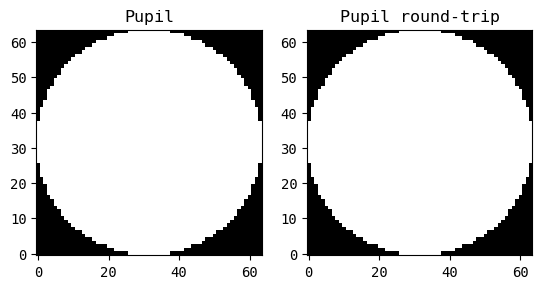

In [2]:
# --- 1.1 Scaled Fourier transforms --------------------------------------
N = 64           # pixels
D=1.0          # m (aperture diameter)
delta_x = D/64   # m per pixel (a 1 m aperture sampled on 64 pixels)

pupil = aotools.circle(N/2, N)          # centred disk, radius N/2 px

# Forward transform (pupil -> focal-plane field) and back
E_focal    = aotools.ft2(pupil, delta=delta_x)
pupil_back = aotools.ift2(E_focal, delta_f=1/(N*delta_x)).real

print('ft2/ift2 round-trip max error:', np.abs(pupil_back - pupil).max())

delta_f = 1/(N*delta_x)
print(f'Pupil pixel scale        : {delta_x:.4f} m/pxl')
print(f'Fourier pixel scale      : {delta_f:.2f} 1/m')
print(f'focal-plane angular pixel scale: {WAVELENGTH*delta_f*206265:.3f} arcsec/pxl  (= lambda/(N*delta_x))')


plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(pupil, cmap='gray')
plt.title('Pupil')
plt.subplot(1, 2, 2)
plt.imshow(pupil_back, cmap='gray')
plt.title('Pupil round-trip')
plt.show()

### 1.2 From pupil to PSF: the Airy pattern

The focal-plane **intensity** PSF is $|\mathcal{F}\{P\}|^2$. 

For a circular pupil of diameter $D$ this is the Airy pattern: a central peak of full width $\approx 1.03\,\lambda/D$ (FWHM), a first zero at $1.22\,\lambda/D$, and $\approx 84\%$ of the light within the first dark ring.

Zero-padding the pupil by a factor `pad_factor` samples the PSF `pad_factor`× finer — a minimum of a factor 2 is necessary to avoid aliasing/artifact (Nyquist-Shannon sampling theorem).

focal-plane pixel scale: 6.45 mas/pxl
diffraction limit lambda/D = 103.1 mas


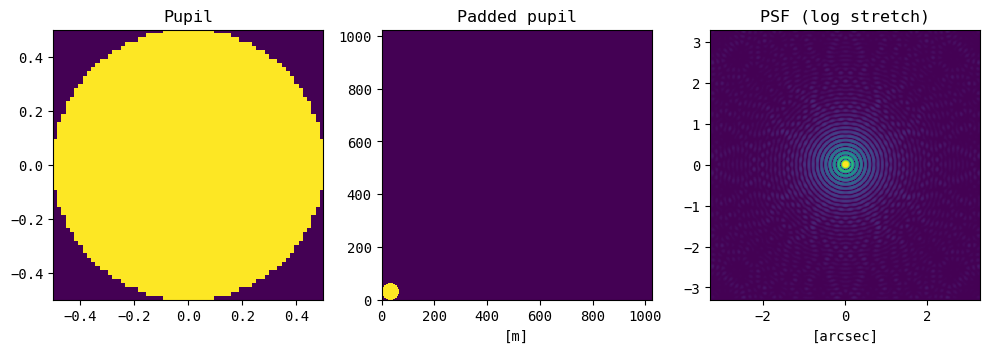

In [3]:
# --- 1.2 Diffraction-limited PSF of a circular aperture -----------------
N   = 64              # pupil pixels across the array
D   = 1.0              # telescope diameter [m]
delta_x = D / N        # m/pxl
pad_factor = 16                # zero-padding factor -> oversampled PSF

pupil = aotools.circle(D/delta_x/2, N)

# Place the pupil in a larger (padded) array -> finer sampling in the focal plane
padded_pupil = np.zeros((N*pad_factor, N*pad_factor))
padded_pupil[:N, :N] = pupil

# E-field in the pupil plane
wavefront = padded_pupil * np.exp(1j*0)  # flat wavefront; the np.exp is not necessary, but included for clarity
# E-field in the focal plane
E_focal = aotools.ft2(wavefront, delta=delta_x)
# Pupil -> focal plane
psf = np.abs(E_focal)**2
psf /= psf.max()

# Focal-plane scales
fpxl_rad    = WAVELENGTH / (N*pad_factor*delta_x)     # rad per focal-plane pixel
fpxl_arcsec = fpxl_rad * 206265                # arcsec per focal-plane pixel
print(f'focal-plane pixel scale: {fpxl_arcsec*1000:.2f} mas/pxl')
print(f'diffraction limit lambda/D = {WAVELENGTH/D*206265*1000:.1f} mas')

fig, ax = plt.subplots(1, 3, figsize=(10, 4.5))


im0 = ax[0].imshow(pupil, extent=[-D/2, D/2, -D/2, D/2])
ax[0].set_title('Pupil'); ax[1].set_xlabel('[m]')

im0 = ax[1].imshow(padded_pupil)
ax[1].set_title('Padded pupil')
ax[1].set_xlabel('[m]')

ext = N*pad_factor/2 * fpxl_arcsec
im1 = imshow_norm(psf, stretch=LogStretch(a=1e4), interval=PercentileInterval(99.95),
                  ax=ax[2], extent=[-ext, ext, -ext, ext])
ax[2].set_title('PSF (log stretch)'); ax[2].set_xlabel('[arcsec]')
plt.tight_layout()

### 1.3 Measuring a PSF
**First zero, EE50, FWHM**

Because the Airy pattern is circularly symmetric, `aotools.azimuthal_average` reduces it to a 1-D profile. From it we measure the **first zero** and the **encircled energy** (`aotools.encircled_energy`), then the **FWHM** and the **MTF** — the modulus of the FT of the PSF — which cuts off at $D/\lambda$ cycles per radian: no spatial frequency beyond the telescope aperture gets through.

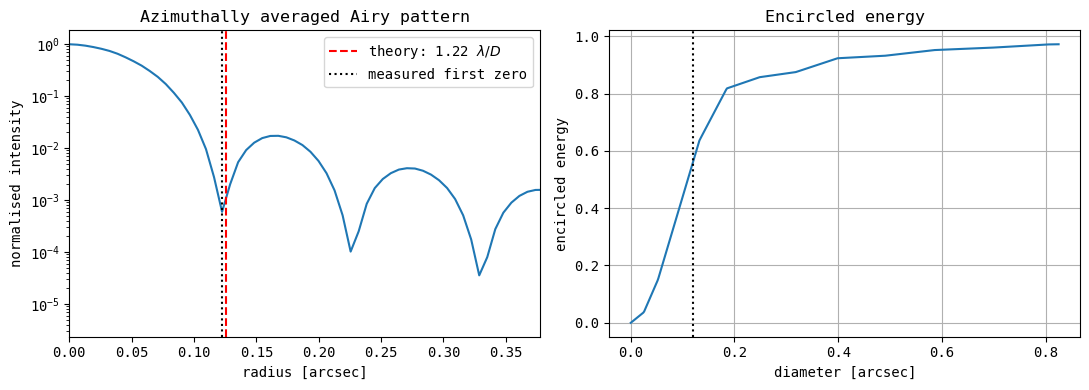

FWHM = 0.103 arcsec = 1.00 lambda/D  (Airy: 1.03)
first Airy zero : measured 0.122 arcsec | theory 0.126 arcsec
EE50 diameter   : 0.121 arcsec = 1.17 lambda/D (Airy: ~1.1)


In [15]:
# --- 1.3 Measuring the Airy pattern -------------------------------------
# The PSF is circularly symmetric -> azimuthal average (aotools.azimuthal_average)
cc = psf.shape[0]//2
box=128
azi = aotools.azimuthal_average(psf[cc-box:cc+box, cc-box:cc+box])
r_arcsec = np.arange(len(azi)) * fpxl_arcsec


# First zero of the Airy pattern: theory 1.22 lambda/D
first_zero = 1.22 * WAVELENGTH / D * 206265   # arcsec
# locate the measured first zero: the first LOCAL minimum of the profile
# (searching a window for the global min would jump to the 2nd/3rd zero)
i_th = np.argmin(np.abs(r_arcsec - first_zero))
i_zero = int(np.argmax(np.diff(azi[:i_th+8]) > 0))   # first index where the profile rises again

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(r_arcsec, azi)
ax[0].axvline(first_zero, color='r', ls='--', label='theory: 1.22 $\\lambda/D$')
ax[0].axvline(r_arcsec[i_zero], color='k', ls=':', label='measured first zero')
ax[0].set_xlabel('radius [arcsec]'); ax[0].set_ylabel('normalised intensity')
ax[0].semilogy()
ax[0].set_title('Azimuthally averaged Airy pattern')
ax[0].legend(); ax[0].set_xlim(0, 3*first_zero)



# Encircled energy curve (aotools.encircled_energy)
box=128
diam, ee = aotools.encircled_energy(psf[cc-box:cc+box, cc-box:cc+box], eeDiameter=False)
ee50 = aotools.encircled_energy(psf, fraction=0.5)

ax[1].plot(diam*fpxl_arcsec, ee)
ax[1].axvline(ee50*fpxl_arcsec, color='k', ls=':', label='EE50 diameter')
ax[1].set_xlabel('diameter [arcsec]'); ax[1].set_ylabel('encircled energy')
ax[1].set_title('Encircled energy'); ax[1].grid(True)
plt.tight_layout()
plt.show()

# FWHM from the azimuthal average
# azi = aotools.azimuthal_average(psf)
half = np.where(azi < azi.max()/2)[0]
fwhm_px = 2*half[0]
print(f'FWHM = {fwhm_px*fpxl_rad*206265:.3f} arcsec = {fwhm_px*fpxl_rad/WAVELENGTH*D:.2f} lambda/D  (Airy: 1.03)')
print(f'first Airy zero : measured {r_arcsec[i_zero]:.3f} arcsec | theory {first_zero:.3f} arcsec')
print(f'EE50 diameter   : {ee50*fpxl_arcsec:.3f} arcsec = {ee50*fpxl_rad/WAVELENGTH*D:.2f} lambda/D (Airy: ~1.1)')


### Exercise 1 — pupils and diffraction
1. The diffraction limit $\lambda/D$ for $D = 1$ m at $\lambda = 500$ nm is $\approx 0.1$ arcsec. What is it at $\lambda = 2.2\,\mu$ m (K band)? 
2. **Padding:** change `pad_factor` (4, 8, 16). 
   1. What happens to the PSF pixel scale (`fpxl_arcsec`) and to the *measured* first zero? 
   2. What happen to the encircled enery
   3. More advanced radial profile using Photutils (see below)
3. Compute the PSF of an **annular** pupil (a disk minus a smaller disk) or a pupil with spider vanes, and measure its FWHM and EE50. How do they change?
   1. Compute the radial profiles and compare them to the circular pupil

<br>

> **Notes** — *not part of the final exercise text*
> 
> *Additional comments / ideas*
> 
> Other questions
> - impact of sampling and padding on theory vs measured zero of Airy pattern
> - encircled energy : why isn't it 0.5 ?
> 
> 
> More advanced
> (3. From the MTF plot: at what spatial frequency (cycles/arcsec) does the MTF reach zero? Compare with $D/\lambda$.)


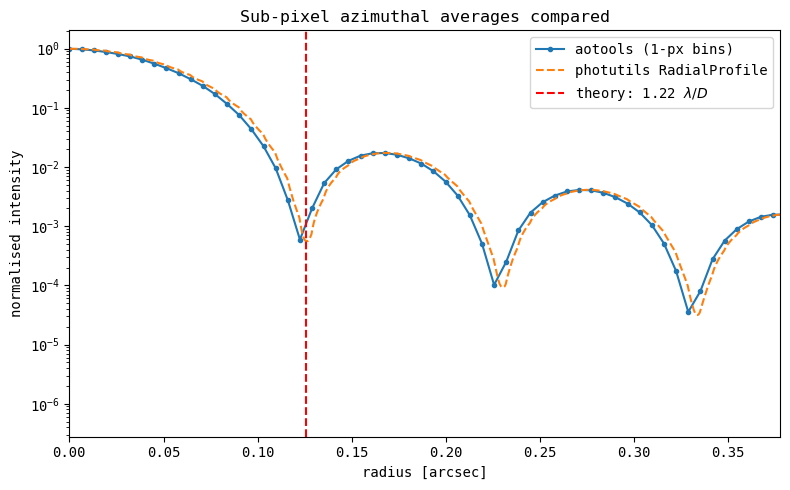

In [16]:
# --- Exercice 2.3: Sub-pixel azimuthal average with photutils ----------------------------
# photutils.profiles.RadialProfile uses fractional-pixel-weighted annuli,
# which gives a true sub-pixel azimuthal average (each pixel contributes
# to annuli proportionally to its fractional overlap).

from photutils.profiles import RadialProfile

# RadialProfile expects the center in (x, y) pixel coordinates
box=128
data = psf[cc-box:cc+box, cc-box:cc+box]
ny, nx = data.shape   # rows, cols
center_xy = ((nx-1)/2, (ny-1)/2)   # (x, y) = (col, row) of the PSF peak
bin_width = 0.1   # pixels
r_max = np.hypot(nx/2, ny/2)       # max radius: centre to farthest corner
bins = np.arange(0, r_max + bin_width, bin_width)

rp = RadialProfile(data, center_xy, radii=bins, error=None)
azi_phot = rp.profile
# Compute bin centres ourselves — rp.radius length can differ from
# rp.profile depending on the photutils version
bin_centers = 0.5 * (bins[:-1] + bins[1:])
n = min(len(bin_centers), len(azi_phot))
r_phot_arcsec = bin_centers[:n] * fpxl_arcsec   # [pixels] -> [arcsec]
azi_phot = azi_phot[:n]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(r_arcsec, azi, 'o-', ms=3, label='aotools (1-px bins)')
ax.plot(r_phot_arcsec, azi_phot, '--', lw=1.5, label='photutils RadialProfile')
ax.axvline(first_zero, color='r', ls='--', label='theory: 1.22 $\\lambda/D$')
ax.set_xlabel('radius [arcsec]'); ax.set_ylabel('normalised intensity')
ax.semilogy()
ax.set_title('Sub-pixel azimuthal averages compared')
ax.legend(); ax.set_xlim(0, 3*first_zero)
plt.tight_layout()
plt.show()

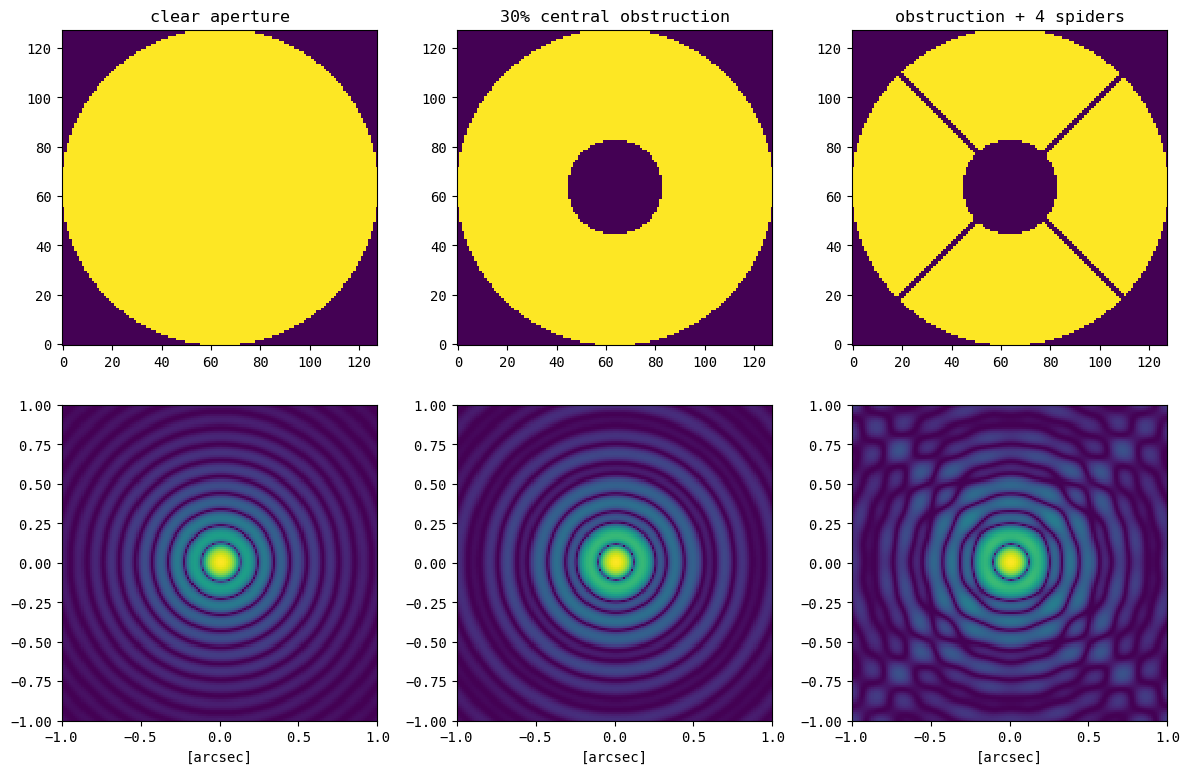

In [17]:
# --- Exercise 3: annular pupil and spider vanes --------------------------
N = 128; D = 1.0; delta_x = D/N; PAD = 8

def make_pupil(N, eps=0.0, n_spiders=0, spider_width=0.02):
    '''Circular pupil with a central obstruction (eps) and spider vanes.'''
    n_spiders = n_spiders // 2
    pupil = aotools.circle(N/2, N)
    if eps > 0:
        pupil = pupil - aotools.circle(eps*N/2, N)
    if n_spiders > 0:
        # Coordinate grids centred on the pupil (origin at the array centre)
        yy, xx = np.mgrid[0:N, 0:N] - N/2
        r = np.hypot(xx, yy)          # radial distance from centre [pixels]
        theta = np.arctan2(yy, xx)   # azimuthal angle [radians]
        # Each loop iteration creates a pair of opposite vanes (a spider is
        # two vanes 180° apart), so n_spiders was halved above.
        for k in range(n_spiders):
            # Vane axis angle: start at 45°, evenly spaced around the pupil
            ang = np.deg2rad(45 + k*180/n_spiders)
            # Perpendicular distance from each pixel to the vane axis.
            # r*sin(theta - ang) is the cross-product form: it gives the
            # shortest distance from the point (r, theta) to the line
            # through the origin at angle `ang`.
            d_perp = np.abs(r*np.sin(theta - ang))   # distance to the vane axis
            # Mask out pixels within half the spider width of the vane axis.
            # spider_width is a fraction of the pupil diameter.
            pupil = pupil * (d_perp > spider_width*N/2)
    return pupil

fig, ax = plt.subplots(2, 3, figsize=(12, 8))
cases = [(0.0, 0, 'clear aperture'),
         (0.3, 0, '30% central obstruction'),
         (0.3, 4, 'obstruction + 4 spiders')]
for col, (eps, n_sp, label) in enumerate(cases):
    pupil = make_pupil(N, eps=eps, n_spiders=n_sp)
    padded = np.zeros((N*PAD, N*PAD)); padded[:N, :N] = pupil
    psf = np.abs(aotools.ft2(padded, delta=delta_x))**2
    psf /= psf.max()
    ext = N*PAD/2 * WAVELENGTH/(N*PAD*delta_x) * 206265
    ax[0, col].imshow(pupil); ax[0, col].set_title(label)
    imshow_norm(psf, stretch=LogStretch(a=1e4), ax=ax[1, col],
                 extent=[-ext, ext, -ext, ext])
    hfov=1
    ax[1, col].set_xlim(-hfov, hfov)
    ax[1, col].set_ylim(-hfov, hfov)
    ax[1, col].set_xlabel('[arcsec]')
plt.tight_layout()
